# In this script we estimate the time spent by Juno within a plasmoid path

In [1]:
import pandas as pd
import datetime as dt
import numpy as np 
import glob
import matplotlib.pyplot as plt 
import matplotlib.patches as patches

from matplotlib.ticker import AutoMinorLocator

from scipy.constants import m_p
from scipy.optimize import curve_fit

from JunoPy.spice import InitSpiceKernels, get_juno_position
from JunoPy.mag import MagData
from JunoPy.library import convert_pos_spherical

In [2]:
# Get Juno trajectory in JUNO_MAG_VIP4 coordinate
InitSpiceKernels()
start = dt.datetime(2016, 6, 20, 17, 30)
end   = dt.datetime(2020, 7, 27, 16)
time_array = pd.date_range(
        start=start, end=end, freq='H').to_pydatetime().tolist()

position_vip4, _ = get_juno_position(time_array, coordsystem='JUNO_MAG_VIP4')
position_jss, _ = get_juno_position(time_array)

LT = 6 / 90 * np.arctan2(position_jss[:, 1], position_jss[:, 0]) * 180 / np.pi + 12

Define $\tau(r)$  as the time spent by Juno in the plasmoid path i.e. 

between $\pm r$ of the magnetic equator, beyond 40 R$_J$ in radial distance for LT in the range [00-04] and [18-24]

In [3]:
N = 40
radius = np.geomspace(5000, 20 * 71492, N) / 71492  # Radius in Rj

rho = np.sqrt(position_vip4[:, 0]**2 + position_vip4[:, 1]**2)
z = position_vip4[:, 2] * 1.0


z = z[(rho > 40) & (((LT < 4) & (LT > 0) | ((LT < 24) & (LT > 18))))]
rho = rho[(rho > 40) & (((LT < 4) & (LT > 0) | ((LT < 24) & (LT > 18))))]

print(z.shape, rho.shape)

tau = np.zeros(N)
for i, r in enumerate(radius):
    
    z_filtered = z[(z > -r) & (z < r)]
    tau[i] = len(z_filtered)
    


(22077,) (22077,)


In [4]:
# fit a linear function between radius and tau
def linear_function(x, a, b):
    return x**a * b

fitparams, _ = curve_fit(linear_function, radius, tau)

def calc_tau(r, a=fitparams[0], b=fitparams[1]):
    return r**a * b

fitparams

array([  1.07524239, 269.09690144])

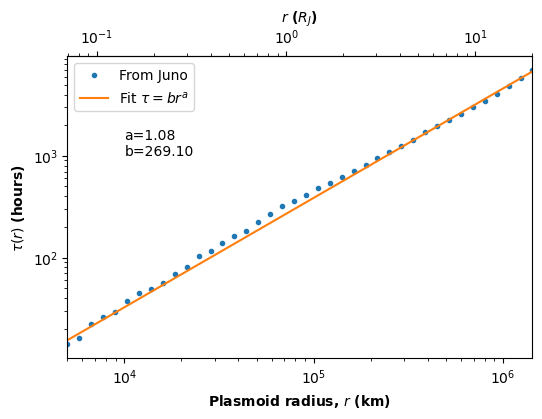

In [5]:
# Plot figure
def plot_variation_tau(radius, tau):
    """
    """
    r = radius * 71492
    
    fig, ax = plt.subplots(1, 1, sharex=True, dpi=100)
    
    ax.loglog(r, tau, '.')
    ax.set_xlim([r[0], r[-1]]) 
    
    
    ax.loglog(r, calc_tau(radius))
    
    ax_secondary = ax.secondary_xaxis("top", functions=(lambda x: x/71492, lambda x: x*71492))
    ax_secondary.set_xlabel('$r$ ($R_J$)', weight='bold')
    
    
    ax.set_xlim([r[0], r[-1]]) 
    ax.set_xlabel('Plasmoid radius, $r$ (km)', weight='bold')
    ax.set_ylabel(r'$\tau (r)$ (hours)', weight='bold')
    
    ax.legend(['From Juno', r'Fit $\tau=b r^a$'])
    ax.text(1e4, 1e3, 'a={:.2f}\nb={:.2f}'.format(fitparams[0], fitparams[1]))
    fig.savefig('out_images/tau_vs_r.png', bbox_inches='tight')
    plt.show()
    
plot_variation_tau(radius, tau)

In [13]:
# Plot the calculated period between consequtive plasmoid release.

def calc_dt(radius, tau, sum_time, v=400):
    return np.pi / 2  * (radius * 71492) * tau / v / sum_time


def calc_various(r, sumTi):

    rho = 0.01 * m_p * 16 * 1e6
    ar = 10
    
    dt = calc_dt(r, calc_tau(r), sumTi, v=400)
    mdot = rho * np.pi * (r * 71492e3)**2 * (ar * r * 71492e3) / (dt * 3600)
    
    print('Radius : {:.2f} Rj'.format(r))
    print('Tau(r) : {:.2f} hours'.format(calc_tau(r)))
    print('Sum Ti : {:.2f} hours'.format(sumTi / 3600))
    print('Dt     : {:.2f} hours'.format(dt))
    print('Mdot   : {:.2f} kg/s'.format(mdot))

    
radius_self = 5000 / 71492 * 8
sum_time_self = 89 * 60 * 8
calc_various(radius_self, sum_time_self)

print('-----------')

radius_vogt2020 = 10 * 8
sum_time_vogt2020 = 85 * 60 * 232 * 8
calc_various(radius_vogt2020, sum_time_vogt2020)


Radius : 0.56 Rj
Tau(r) : 144.12 hours
Sum Ti : 11.87 hours
Dt     : 0.53 hours
Mdot   : 0.28 kg/s
-----------
Radius : 80.00 Rj
Tau(r) : 29935.86 hours
Sum Ti : 2629.33 hours
Dt     : 71.03 hours
Mdot   : 6151.15 kg/s


In [ ]:
dt = np.pi / 2 * (radius * 71492) * tau / 400 / (89 * 60)  # This is incorrect since it will change . 

rho = 0.01 * m_p * 16 * 1e6
ar = 10
mdot = rho * np.pi * (radius * 71492e3)**2 * (ar * radius * 71492e3) / (dt * 3600)

In [ ]:
calc_tau(80) / 3600